# Exploración de datos · Deserción en la Formación Profesional Integral (SENA)

**Proyecto:** Alerta de Permanencia, entrega 1.
**Fuente:** datos abiertos del SENA, *Deserción de la Formación Profesional Integral*, archivo descargado el 23/10/2026 (`data/raw/DESERCION_FPI_20261023.csv`, versionado con DVC).
**Unidad de análisis:** la ficha (grupo de aprendices de un programa en un centro de formación).

Objetivo del notebook: entender la calidad y la estructura de los datos, describir dónde se concentra la deserción y definir la variable objetivo del modelo supervisado.

In [23]:
import os
from pathlib import Path

os.environ['LOKY_MAX_CPU_COUNT'] = '4'  # núcleos físicos de tu PC (Administrador de tareas > Rendimiento > CPU)

# Raíz del proyecto: sube desde el notebook hasta encontrar la carpeta 'data'
RAIZ = Path.cwd()
while not (RAIZ / 'data').is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError('No encontré la carpeta data. Abre el notebook dentro de dsa-grupo33-entrega1.')
    RAIZ = RAIZ.parent

RAW = RAIZ / 'data' / 'raw'
PROCESSED = RAIZ / 'data' / 'processed'
FIGURAS = RAIZ / 'reports' / 'figures'
for carpeta in (RAW, PROCESSED, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

FIG = FIGURAS.as_posix() + '/'  # las celdas de gráficos usan FIG + 'nombre.png'

archivos = sorted(RAW.glob('DESERCION*.csv'))
if not archivos:
    raise FileNotFoundError(f'Copia el CSV original en {RAW}')
RUTA = archivos[-1]

print('Proyecto:', RAIZ)
print('Datos crudos:', RUTA.name)

Proyecto: c:\Users\jmaur\OneDrive\Documentos\MIAD - UNIANDES\Tercer Semestre\Despliegue de Soluciones Analiticas\Proyecto\dsa-grupo33-entrega1
Datos crudos: DESERCION_DE_LA_FORMACIÓN_PROFESIONAL_INTEGRAL_20261023.csv


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Paleta: gris para el contexto, un acento para lo que la gráfica señala
GRIS, GRIS_OSC, ACENTO, ALERTA, TINTA = '#B8C2BB', '#5E6A62', '#1F7A45', '#B42318', '#14201A'
plt.rcParams.update({
    'font.family': ['Inter', 'DejaVu Sans'], 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9AA79F', 'axes.labelcolor': '#4F5C54', 'xtick.color': '#4F5C54', 'ytick.color': '#4F5C54',
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'
})
pct = lambda x, d=1: f'{x*100:.{d}f} %'.replace('.', ',')
miles = lambda n: f'{n:,.0f}'.replace(',', '.')


## 1. Carga y limpieza

El archivo trae tres problemas de formato: separador `;`, textos envueltos en comillas triples (`\"\"\"REGIONAL BOLIVAR\"\"\"`) y caracteres mal codificados (`NARIÃ‘O` en lugar de `NARIÑO`). Se corrigen al cargar.

In [25]:

def arreglar(v):
    # Quita comillas sobrantes y repara texto UTF-8 leído como Windows-1252
    if not isinstance(v, str):
        return v
    v = v.strip().strip('"').strip()
    try:
        return v.encode('cp1252').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return v

crudo = pd.read_csv(RUTA, sep=';', encoding='utf-8-sig', dtype=str)
crudo.columns = [arreglar(c).replace('AÑO', 'ANIO') for c in crudo.columns]
for c in crudo.columns:
    crudo[c] = crudo[c].map(arreglar)
print('Filas x columnas:', crudo.shape)
crudo.head(3)

Filas x columnas: (42080, 15)


,CODIGO_REGIONAL,NOMBRE_REGIONAL,CODIGO_CENTRO,NOMBRE_CENTRO,IDENTIFICADOR_UNICO_FICHA,FECHA_INICIO_FICHA,FECHA_TERMINACION_FICHA,CODIGO_PROGRAMA,VERSION_PROGRAMA,NOMBRE_PROGRAMA_FORMACION,NIVEL_FORMACION,MODALIDAD_FORMACION,TOTAL_APRENDICES_MATRICULADOS,DESERTORES_ANIO_ACTUAL,PERIODO
0,13,REGIONAL BOLIVAR,9304,CENTRO DE COMERCIO Y SERVICIOS,12709991,27/02/2023,16/12/2024,635503,103,COCINA.,TECNICO,PRESENCIAL,33,0,202.402
1,19,REGIONAL CAUCA,9113,CENTRO AGROPECUARIO,12860879,17/10/2023,01/03/2025,635604,1,SERVICIOS DE BARISMO,TECNICO,PRESENCIAL,21,0,202.402
2,76,REGIONAL VALLE,9544,CENTRO DE BIOTECNOLOGIA INDUSTRIAL,12710859,27/02/2023,16/12/2024,233101,1,SISTEMAS.,TECNICO,PRESENCIAL,39,0,202.402


In [26]:
# Valores faltantes por columna
crudo.isna().sum()[lambda s: s > 0]

NIVEL_FORMACION                  1
MODALIDAD_FORMACION              1
TOTAL_APRENDICES_MATRICULADOS    1
DESERTORES_ANIO_ACTUAL           1
PERIODO                          1
dtype: int64

In [27]:
# La única fila incompleta está truncada en el archivo fuente: se descarta
display(crudo[crudo.TOTAL_APRENDICES_MATRICULADOS.isna()][['NOMBRE_REGIONAL', 'NOMBRE_CENTRO', 'IDENTIFICADOR_UNICO_FICHA', 'NOMBRE_PROGRAMA_FORMACION']])
df = crudo.dropna(subset=['TOTAL_APRENDICES_MATRICULADOS']).copy()

df['matriculados'] = df.TOTAL_APRENDICES_MATRICULADOS.astype(int)
df['desertores'] = df.DESERTORES_ANIO_ACTUAL.astype(int)
df['fecha_inicio'] = pd.to_datetime(df.FECHA_INICIO_FICHA, dayfirst=True)
df['fecha_fin'] = pd.to_datetime(df.FECHA_TERMINACION_FICHA, dayfirst=True)
df['duracion_dias'] = (df.fecha_fin - df.fecha_inicio).dt.days
df['tasa_desercion'] = df.desertores / df.matriculados
print('Filas válidas:', len(df))

,NOMBRE_REGIONAL,NOMBRE_CENTRO,IDENTIFICADOR_UNICO_FICHA,NOMBRE_PROGRAMA_FORMACION
36196,REGIONAL VALLE,CENTRO NAUTICO PESQUERO DE BUENAVENTURA,12903407,OMI 1.38 SENSIBILIZACION CON RESPECTO AL MEDIO...


Filas válidas: 42079


## 2. Calidad y estructura

In [28]:
chequeos = {
    'Fichas duplicadas (IDENTIFICADOR_UNICO_FICHA)': df.IDENTIFICADOR_UNICO_FICHA.duplicated().sum(),
    'Desertores > matriculados': (df.desertores > df.matriculados).sum(),
    'Fecha fin anterior a inicio': (df.duracion_dias < 0).sum(),
    'Valores distintos de PERIODO': df.PERIODO.nunique(),
    'Regionales': df.NOMBRE_REGIONAL.nunique(),
    'Centros de formación': df.CODIGO_CENTRO.nunique(),
    'Programas (código)': df.CODIGO_PROGRAMA.nunique(),
}
pd.Series(chequeos, name='valor').to_frame()

,valor
Fichas duplicadas (IDENTIFICADOR_UNICO_FICHA),0
Desertores > matriculados,0
Fecha fin anterior a inicio,0
Valores distintos de PERIODO,1
Regionales,33
Centros de formación,117
Programas (código),2194


In [29]:
print('PERIODO:', df.PERIODO.unique(), '-> un solo corte (2024, periodo 02)')
print('Inicio de fichas:', df.fecha_inicio.min().date(), 'a', df.fecha_inicio.max().date())
print('Fin de fichas:   ', df.fecha_fin.min().date(), 'a', df.fecha_fin.max().date())
df[['matriculados', 'desertores', 'duracion_dias', 'tasa_desercion']].describe().round(3)

PERIODO: ['202.402'] -> un solo corte (2024, periodo 02)
Inicio de fichas: 2020-11-03 a 2024-02-28
Fin de fichas:    2024-01-01 a 2026-12-31


,matriculados,desertores,duracion_dias,tasa_desercion
count,42079.000,42079.000,42079.000,42079.000
mean,34.392,1.249,429.637,0.026
std,21.348,6.436,311.335,0.097
min,1.000,0.000,0.000,0.000
25%,22.000,0.000,33.000,0.000
50%,27.000,0.000,457.000,0.000
75%,35.000,0.000,682.000,0.000
max,208.000,84.000,1396.000,1.000


In [30]:
for col in ['NIVEL_FORMACION', 'MODALIDAD_FORMACION']:
    print(df[col].value_counts().to_frame('fichas').assign(porcentaje=lambda t: (t.fichas / t.fichas.sum() * 100).round(1)), '\n')

                        fichas  porcentaje
NIVEL_FORMACION                           
TECNICO                  16832        40.0
CURSO ESPECIAL           14284        33.9
TECNOLOGO                10259        24.4
OPERARIO                   423         1.0
EVENTO                     142         0.3
AUXILIAR                   128         0.3
PROFUNDIZACION TECNICA      11         0.0 

                     fichas  porcentaje
MODALIDAD_FORMACION                    
PRESENCIAL            32343        76.9
VIRTUAL                9592        22.8
A DISTANCIA             144         0.3 



## 3. ¿Cuánta deserción hay y cómo se distribuye entre fichas?

In [31]:
M, D = df.matriculados.sum(), df.desertores.sum()
print(f'Matriculados: {miles(M)} | Desertores: {miles(D)} | Tasa global: {pct(D / M)}')
print(f'Fichas con al menos un desertor: {pct((df.desertores > 0).mean())}')

t = df.tasa_desercion
etiquetas_banda = ['0 %', 'menos de 5 %', '5–10 %', '10–20 %', '20 % o más']
bandas = pd.Series(np.select([t == 0, t < 0.05, t < 0.10, t < 0.20], etiquetas_banda[:4], etiquetas_banda[4]), index=df.index)
bandas = pd.Categorical(bandas, categories=etiquetas_banda, ordered=True)
bandas = pd.Series(bandas, index=df.index)
tabla_bandas = bandas.value_counts().sort_index().to_frame('fichas')
tabla_bandas['porcentaje'] = tabla_bandas.fichas / len(df)
tabla_bandas

Matriculados: 1.447.177 | Desertores: 52.575 | Tasa global: 3,6 %
Fichas con al menos un desertor: 24,3 %


,fichas,porcentaje
0 %,31852,0.756957
menos de 5 %,5346,0.127047
5–10 %,2481,0.058961
10–20 %,1115,0.026498
20 % o más,1285,0.030538


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.


Las figuras se guardarán en: C:\Users\jmaur\OneDrive\Documentos\MIAD - UNIANDES\Tercer Semestre\Despliegue de Soluciones Analiticas\Proyecto\dsa-grupo33-entrega1\reports\figures


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

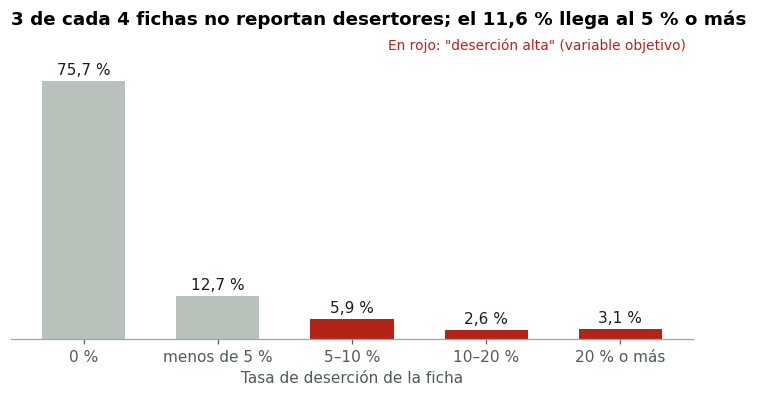

In [32]:
from pathlib import Path


print('Las figuras se guardarán en:', Path(FIG).resolve())

fig, ax = plt.subplots(figsize=(8, 3.6))
colores = [GRIS, GRIS, ALERTA, ALERTA, ALERTA]
barras = ax.bar(tabla_bandas.index.astype(str), tabla_bandas.porcentaje, color=colores, width=0.62)
for b, v in zip(barras, tabla_bandas.porcentaje):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, pct(v), ha='center', va='bottom', fontsize=10, color=TINTA)
ax.set_title(f'3 de cada 4 fichas no reportan desertores; el {pct((df.tasa_desercion >= 0.05).mean())} llega al 5 % o más')
ax.set_xlabel('Tasa de deserción de la ficha')
ax.set_yticks([]); ax.spines['left'].set_visible(False); ax.set_ylim(0, tabla_bandas.porcentaje.max() * 1.18)
ax.text(0.99, 0.95, 'En rojo: "deserción alta" (variable objetivo)', transform=ax.transAxes, ha='right', fontsize=9, color=ALERTA)
fig.savefig(FIG + 'fig1_distribucion_tasa_fichas.png'); plt.show()

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

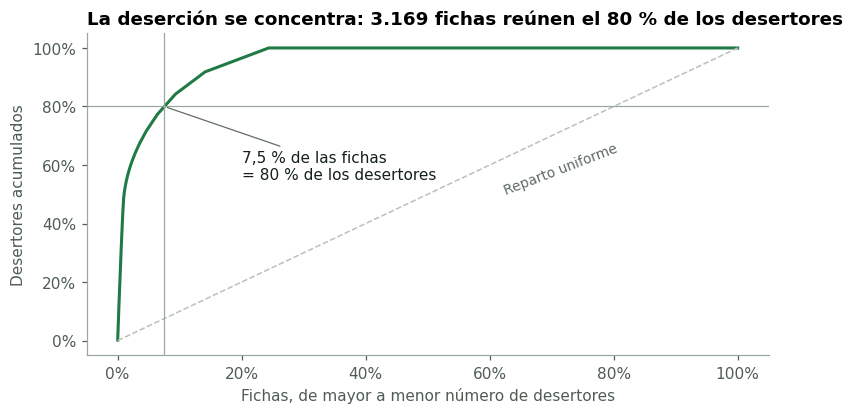

In [33]:
# Concentración: ¿qué porcentaje de fichas reúne la mayoría de desertores?
orden = df.sort_values('desertores', ascending=False)
acum = orden.desertores.cumsum() / D
x = np.arange(1, len(orden) + 1) / len(orden)
n80 = int((acum < 0.8).sum()) + 1

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(x, acum, color=ACENTO, lw=2)
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls='--')
ax.axhline(0.8, color='#9AA79F', lw=0.8); ax.axvline(n80 / len(df), color='#9AA79F', lw=0.8)
ax.annotate(f'{pct(n80 / len(df))} de las fichas\n= 80 % de los desertores', xy=(n80 / len(df), 0.8), xytext=(0.2, 0.55),
            fontsize=10, color=TINTA, arrowprops=dict(arrowstyle='-', color='#5E6A62', lw=0.8))
ax.text(0.62, 0.5, 'Reparto uniforme', color=GRIS_OSC, fontsize=9, rotation=21)
ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
ax.set_xlabel('Fichas, de mayor a menor número de desertores'); ax.set_ylabel('Desertores acumulados')
ax.set_title(f'La deserción se concentra: {miles(n80)} fichas reúnen el 80 % de los desertores')
fig.savefig(FIG + 'fig2_concentracion_desertores.png'); plt.show()

## 4. ¿Dónde se concentra? Modalidad, nivel, regional, tamaño y duración

In [34]:
def resumen(grupo):
    t = df.groupby(grupo).agg(fichas=('desertores', 'size'), matriculados=('matriculados', 'sum'),
                              desertores=('desertores', 'sum'), fichas_alta=('tasa_desercion', lambda s: (s >= 0.05).mean()))
    t['tasa'] = t.desertores / t.matriculados
    t['part_desertores'] = t.desertores / D
    return t

mod = resumen('MODALIDAD_FORMACION').sort_values('tasa', ascending=False)
niv = resumen('NIVEL_FORMACION').sort_values('tasa', ascending=False)
display(mod.round(3)); display(niv.round(3))

,fichas,matriculados,desertores,fichas_alta,tasa,part_desertores
MODALIDAD_FORMACION,,,,,,
VIRTUAL,9592,634378,39556,0.201,0.062,0.752
A DISTANCIA,144,3952,95,0.160,0.024,0.002
PRESENCIAL,32343,808847,12924,0.091,0.016,0.246


,fichas,matriculados,desertores,fichas_alta,tasa,part_desertores
NIVEL_FORMACION,,,,,,
EVENTO,142,6926,723,0.211,0.104,0.014
CURSO ESPECIAL,14284,719101,38499,0.132,0.054,0.732
OPERARIO,423,9069,400,0.229,0.044,0.008
TECNOLOGO,10259,269099,5752,0.123,0.021,0.109
AUXILIAR,128,2919,53,0.070,0.018,0.001
TECNICO,16832,439782,7148,0.095,0.016,0.136
PROFUNDIZACION TECNICA,11,281,0,0.000,0.000,0.000


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

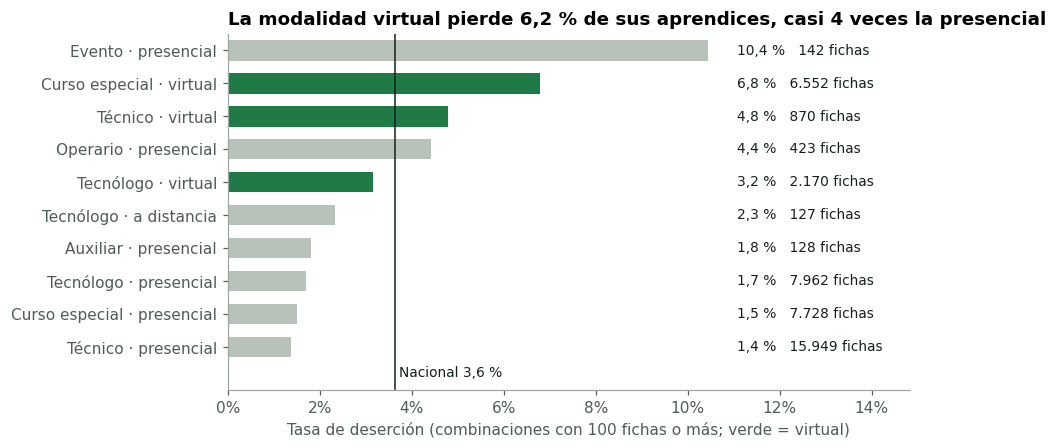

In [35]:
combo = resumen(['NIVEL_FORMACION', 'MODALIDAD_FORMACION'])
combo = combo[combo.fichas >= 100].sort_values('tasa')
NOMBRE_NIVEL = {'TECNICO': 'Técnico', 'TECNOLOGO': 'Tecnólogo', 'CURSO ESPECIAL': 'Curso especial', 'OPERARIO': 'Operario',
                'AUXILIAR': 'Auxiliar', 'EVENTO': 'Evento', 'PROFUNDIZACION TECNICA': 'Profundización técnica'}
etiquetas = [f'{NOMBRE_NIVEL[n]} · {m.lower()}' for n, m in combo.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
col = [ACENTO if m == 'VIRTUAL' else GRIS for _, m in combo.index]
ax.barh(etiquetas, combo.tasa, color=col, height=0.62)
xcol = combo.tasa.max() * 1.06
for i, (v, n) in enumerate(zip(combo.tasa, combo.fichas)):
    ax.text(xcol, i, f'{pct(v)}   {miles(n)} fichas', va='center', fontsize=9, color=TINTA)
ax.axvline(D / M, color=TINTA, lw=1)
ax.text(D / M + 0.0008, -0.9, f'Nacional {pct(D / M)}', fontsize=9, color=TINTA)
ax.set_ylim(-1.3, len(combo) - 0.5); ax.set_xlim(0, combo.tasa.max() * 1.42); ax.xaxis.set_major_formatter(PercentFormatter(1, 0))
ax.set_title(f'La modalidad virtual pierde {pct(mod.loc["VIRTUAL", "tasa"])} de sus aprendices, casi 4 veces la presencial')
ax.set_xlabel('Tasa de deserción (combinaciones con 100 fichas o más; verde = virtual)')
fig.savefig(FIG + 'fig3_tasa_nivel_modalidad.png'); plt.show()

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

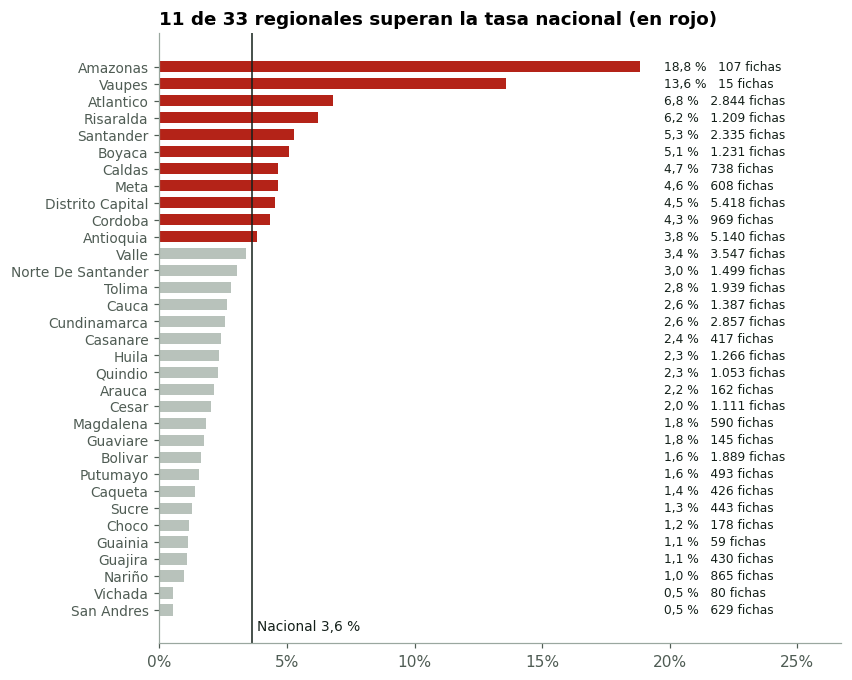

In [36]:
reg = resumen('NOMBRE_REGIONAL').sort_values('tasa')
reg.index = [r.replace('REGIONAL ', '').title() for r in reg.index]

fig, ax = plt.subplots(figsize=(8, 7.2))
col = [ALERTA if v > D / M else GRIS for v in reg.tasa]
ax.barh(reg.index, reg.tasa, color=col, height=0.66)
xcol = reg.tasa.max() * 1.05
for i, (v, n) in enumerate(zip(reg.tasa, reg.fichas)):
    ax.text(xcol, i, f'{pct(v)}   {miles(n)} fichas', va='center', fontsize=8, color=TINTA)
ax.axvline(D / M, color=TINTA, lw=1)
ax.text(D / M + 0.002, -1.2, f'Nacional {pct(D / M)}', fontsize=9, color=TINTA)
ax.set_xlim(0, reg.tasa.max() * 1.42); ax.xaxis.set_major_formatter(PercentFormatter(1, 0))
ax.tick_params(axis='y', labelsize=9)
ax.set_title(f'{(reg.tasa > D / M).sum()} de 33 regionales superan la tasa nacional (en rojo)')
fig.savefig(FIG + 'fig4_tasa_regional.png'); plt.show()

C:\Users\jmaur\AppData\Local\Temp\ipykernel_24776\3840856571.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(grupo).agg(fichas=('desertores', 'size'), matriculados=('matriculados', 'sum'),
C:\Users\jmaur\AppData\Local\Temp\ipykernel_24776\3840856571.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(grupo).agg(fichas=('desertores', 'size'), matriculados=('matriculados', 'sum'),
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not fo

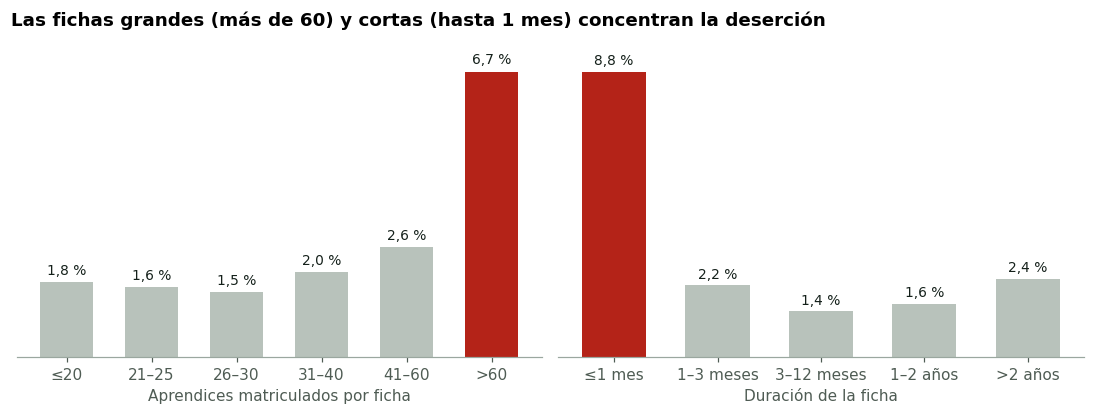

,fichas,matriculados,desertores,fichas_alta,tasa,part_desertores
banda_tamano,,,,,,
≤20,8998,142277,2533,0.134,0.018,0.048
21–25,8808,204670,3363,0.074,0.016,0.064
26–30,9686,272022,4202,0.080,0.015,0.080
31–40,6049,206978,4145,0.105,0.020,0.079
41–60,1844,84815,2204,0.104,0.026,0.042
>60,6694,536415,36128,0.211,0.067,0.687


,fichas,matriculados,desertores,fichas_alta,tasa,part_desertores
banda_duracion,,,,,,
≤1 mes,7902,357679,31351,0.177,0.088,0.596
1–3 meses,5941,353569,7869,0.087,0.022,0.150
3–12 meses,1699,40731,573,0.085,0.014,0.011
1–2 años,20210,520461,8565,0.098,0.016,0.163
>2 años,6327,174737,4217,0.133,0.024,0.080


In [37]:
df['banda_tamano'] = pd.cut(df.matriculados, [0, 20, 25, 30, 40, 60, 300], labels=['≤20', '21–25', '26–30', '31–40', '41–60', '>60'])
df['banda_duracion'] = pd.cut(df.duracion_dias, [-1, 30, 90, 365, 730, 2000], labels=['≤1 mes', '1–3 meses', '3–12 meses', '1–2 años', '>2 años'])
tam = resumen('banda_tamano'); dur = resumen('banda_duracion')

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, t, titulo, clave in [(axs[0], tam, 'Aprendices matriculados por ficha', '>60'), (axs[1], dur, 'Duración de la ficha', '≤1 mes')]:
    col = [ALERTA if str(i) == clave else GRIS for i in t.index]
    b = ax.bar(t.index.astype(str), t.tasa, color=col, width=0.62)
    for bi, v in zip(b, t.tasa):
        ax.text(bi.get_x() + bi.get_width() / 2, v + 0.001, pct(v), ha='center', va='bottom', fontsize=9, color=TINTA)
    ax.set_yticks([]); ax.spines['left'].set_visible(False); ax.set_xlabel(titulo)
fig.suptitle('Las fichas grandes (más de 60) y cortas (hasta 1 mes) concentran la deserción', x=0.01, ha='left', fontweight='bold', fontsize=12)
fig.tight_layout(); fig.savefig(FIG + 'fig5_tamano_duracion.png'); plt.show()
display(tam.round(3)); display(dur.round(3))

## 5. Variable objetivo y línea base del modelo

**Variable objetivo:** `deserción_alta = 1` si la tasa de deserción de la ficha es de 5 % o más. Se eligió este umbral porque separa el 11,6 % de las fichas con más deserción, y es un valor fácil de explicar al coordinador.

**Variables explicativas (conocidas al abrir la ficha):** modalidad, nivel, programa y centro (codificados con su historial de deserción, *target encoding* con validación interna para evitar fuga de información), aprendices matriculados y duración planeada.

La línea base usa `HistGradientBoostingClassifier` y validación cruzada estratificada de 5 particiones. Su propósito es dimensionar el problema y alimentar la maqueta; el modelo final se trabajará en las siguientes entregas.

In [38]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

df['y'] = (df.tasa_desercion >= 0.05).astype(int)
df['mod_c'] = df.MODALIDAD_FORMACION.map({'PRESENCIAL': 0, 'VIRTUAL': 1, 'A DISTANCIA': 2})
df['niv_c'] = df.NIVEL_FORMACION.map({k: i for i, k in enumerate(['TECNICO', 'TECNOLOGO', 'CURSO ESPECIAL', 'OPERARIO', 'AUXILIAR', 'EVENTO', 'PROFUNDIZACION TECNICA'])})
print('Prevalencia de deserción alta:', pct(df.y.mean()))

K = 20  # suavizado del target encoding
def te(train, test, col):
    g = train.groupby(col).y.agg(['sum', 'count']); prior = train.y.mean()
    return test[col].map((g['sum'] + K * prior) / (g['count'] + K)).fillna(prior).values

FEATS = ['mod_c', 'niv_c', 'te_prog', 'te_centro', 'matriculados', 'duracion_dias']
params = dict(max_iter=150, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0, random_state=42)
oof = np.zeros(len(df))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=42).split(df, df.y):
    a, b = df.iloc[tr].copy(), df.iloc[va].copy()
    a['te_prog'] = 0.0; a['te_centro'] = 0.0
    for itr, ite in StratifiedKFold(5, shuffle=True, random_state=1).split(a, a.y):
        a.iloc[ite, a.columns.get_loc('te_prog')] = te(a.iloc[itr], a.iloc[ite], 'CODIGO_PROGRAMA')
        a.iloc[ite, a.columns.get_loc('te_centro')] = te(a.iloc[itr], a.iloc[ite], 'CODIGO_CENTRO')
    b['te_prog'] = te(a, b, 'CODIGO_PROGRAMA'); b['te_centro'] = te(a, b, 'CODIGO_CENTRO')
    modelo = HistGradientBoostingClassifier(**params).fit(a[FEATS], a.y)
    oof[va] = modelo.predict_proba(b[FEATS])[:, 1]

orden = np.argsort(-oof); capt = np.cumsum(df.y.values[orden]) / df.y.sum()
frac = np.arange(1, len(df) + 1) / len(df); c20 = capt[int(0.2 * len(df)) - 1]
print(f'AUC: {roc_auc_score(df.y, oof):.3f} | PR-AUC: {average_precision_score(df.y, oof):.3f} | Top 20 % capta: {pct(c20)}')

Prevalencia de deserción alta: 11,6 %
AUC: 0.775 | PR-AUC: 0.349 | Top 20 % capta: 50,0 %


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

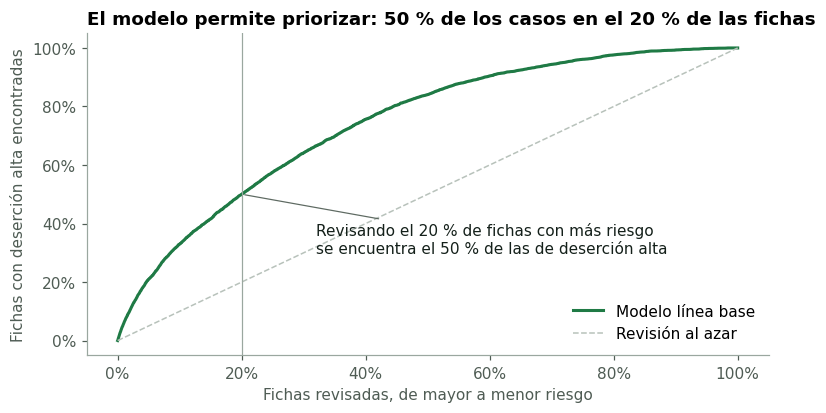

In [39]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(frac, capt, color=ACENTO, lw=2, label='Modelo línea base')
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls='--', label='Revisión al azar')
ax.axvline(0.2, color='#9AA79F', lw=0.8)
ax.annotate(f'Revisando el 20 % de fichas con más riesgo\nse encuentra el {pct(c20, 0)} de las de deserción alta',
            xy=(0.2, c20), xytext=(0.32, 0.3), fontsize=10, color=TINTA, arrowprops=dict(arrowstyle='-', color='#5E6A62', lw=0.8))
ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
ax.set_xlabel('Fichas revisadas, de mayor a menor riesgo'); ax.set_ylabel('Fichas con deserción alta encontradas')
ax.legend(frameon=False, loc='lower right')
ax.set_title(f'El modelo permite priorizar: {pct(c20, 0)} de los casos en el 20 % de las fichas')
fig.savefig(FIG + 'fig6_curva_captura_modelo.png'); plt.show()

## 6. Hallazgos para el producto

1. **Deserción concentrada.** 3,6 % de los aprendices desertaron, pero el 7,5 % de las fichas reúne el 80 % de los desertores: priorizar fichas es más útil que una acción general.
2. **Modalidad virtual.** Tasa de 6,2 % frente a 1,6 % presencial; aporta el 75 % de los desertores con el 23 % de las fichas. El curso especial virtual es la combinación de mayor volumen de deserción.
3. **Fichas grandes y cortas.** Las fichas de más de 60 aprendices (6,7 %) y las de hasta un mes (8,8 %) tienen las tasas más altas.
4. **Diferencias territoriales.** 11 de 33 regionales superan la tasa nacional; Atlántico (6,8 %) es la más alta entre las regionales grandes.
5. **Objetivo del modelo.** El 11,6 % de las fichas tiene deserción alta (≥ 5 %). Una línea base con seis variables conocidas al abrir la ficha logra AUC 0,78 y concentra la mitad de esos casos en el 20 % de fichas con más riesgo.

**Limitaciones:** un solo corte (202402); `DESERTORES_AÑO_ACTUAL` cuenta deserciones del año en curso, de modo que fichas que iniciaron antes de 2024 solo reflejan parte de su historia; no hay variables por aprendiz (edad, estrato, ingresos). Para las siguientes entregas se recomienda incorporar más cortes históricos.

In [40]:
# Conjunto limpio para el modelo (versionado con DVC en data/processed)
cols = ['CODIGO_REGIONAL', 'NOMBRE_REGIONAL', 'CODIGO_CENTRO', 'NOMBRE_CENTRO', 'IDENTIFICADOR_UNICO_FICHA', 'fecha_inicio', 'fecha_fin',
        'duracion_dias', 'CODIGO_PROGRAMA', 'VERSION_PROGRAMA', 'NOMBRE_PROGRAMA_FORMACION', 'NIVEL_FORMACION', 'MODALIDAD_FORMACION',
        'matriculados', 'desertores', 'tasa_desercion', 'y']
limpio = df[cols].rename(columns={'y': 'desercion_alta'})
limpio.to_csv(PROCESSED / 'desercion_fichas_limpio.csv', index=False, encoding='utf-8')
print(limpio.shape); limpio.head()

(42079, 17)


,CODIGO_REGIONAL,NOMBRE_REGIONAL,CODIGO_CENTRO,NOMBRE_CENTRO,IDENTIFICADOR_UNICO_FICHA,fecha_inicio,fecha_fin,duracion_dias,CODIGO_PROGRAMA,VERSION_PROGRAMA,NOMBRE_PROGRAMA_FORMACION,NIVEL_FORMACION,MODALIDAD_FORMACION,matriculados,desertores,tasa_desercion,desercion_alta
0,13,REGIONAL BOLIVAR,9304,CENTRO DE COMERCIO Y SERVICIOS,12709991,2023-02-27,2024-12-16,658,635503,103,COCINA.,TECNICO,PRESENCIAL,33,0,0.0,0
1,19,REGIONAL CAUCA,9113,CENTRO AGROPECUARIO,12860879,2023-10-17,2025-03-01,501,635604,1,SERVICIOS DE BARISMO,TECNICO,PRESENCIAL,21,0,0.0,0
2,76,REGIONAL VALLE,9544,CENTRO DE BIOTECNOLOGIA INDUSTRIAL,12710859,2023-02-27,2024-12-16,658,233101,1,SISTEMAS.,TECNICO,PRESENCIAL,39,0,0.0,0
3,19,REGIONAL CAUCA,9113,CENTRO AGROPECUARIO,12615282,2022-10-06,2024-10-05,730,112005,101,GESTION DEL TALENTO HUMANO,TECNOLOGO,PRESENCIAL,24,0,0.0,0
4,20,REGIONAL CESAR,9520,CENTRO AGROEMPRESARIAL,12715260,2023-03-06,2024-12-13,648,134200,2,RECURSOS HUMANOS .,TECNICO,PRESENCIAL,24,0,0.0,0
